# End-to-end Multi-class classification

In [1]:
# Import TensorFlow
import tensorflow as tf
import tensorflow_hub as hub

print("TensorFlow version:", tf.__version__)  # Should print 2.14.0
print("TensorFlow Hub version:", hub.__version__)  # Should print 0.15.0


2024-08-08 19:39:22.441835: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-08 19:39:22.441890: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-08 19:39:22.441959: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-08-08 19:39:24.053110: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion

TensorFlow version: 2.14.0
TensorFlow Hub version: 0.15.0


In [27]:
# Check for GPU availability
print("GPU","Available (YEEEEESSSSS!!!!!)" if tf.config.list_physical_devices("GPU") else "not available :(")

GPU Available (YEEEEESSSSS!!!!!)


## Getting data ready (turning into Tensors)

Turning our images into tensors (numerical representations)

In [28]:
import pandas as pd
labels_csv = pd.read_csv("/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/labels.csv")
print(labels_csv.describe())
print(labels_csv.head())

                                      id               breed
count                              10222               10222
unique                             10222                 120
top     000bec180eb18c7604dcecc8fe0dba07  scottish_deerhound
freq                                   1                 126
                                 id             breed
0  000bec180eb18c7604dcecc8fe0dba07       boston_bull
1  001513dfcb2ffafc82cccf4d8bbaba97             dingo
2  001cdf01b096e06d78e9e5112d419397          pekinese
3  00214f311d5d2247d5dfe4fe24b2303d          bluetick
4  0021f9ceb3235effd7fcde7f7538ed62  golden_retriever


In [29]:
labels_csv.head()

,id,breed
0,000bec180eb18c7604dcecc8fe0dba07,boston_bull
1,001513dfcb2ffafc82cccf4d8bbaba97,dingo
2,001cdf01b096e06d78e9e5112d419397,pekinese
3,00214f311d5d2247d5dfe4fe24b2303d,bluetick
4,0021f9ceb3235effd7fcde7f7538ed62,golden_retriever


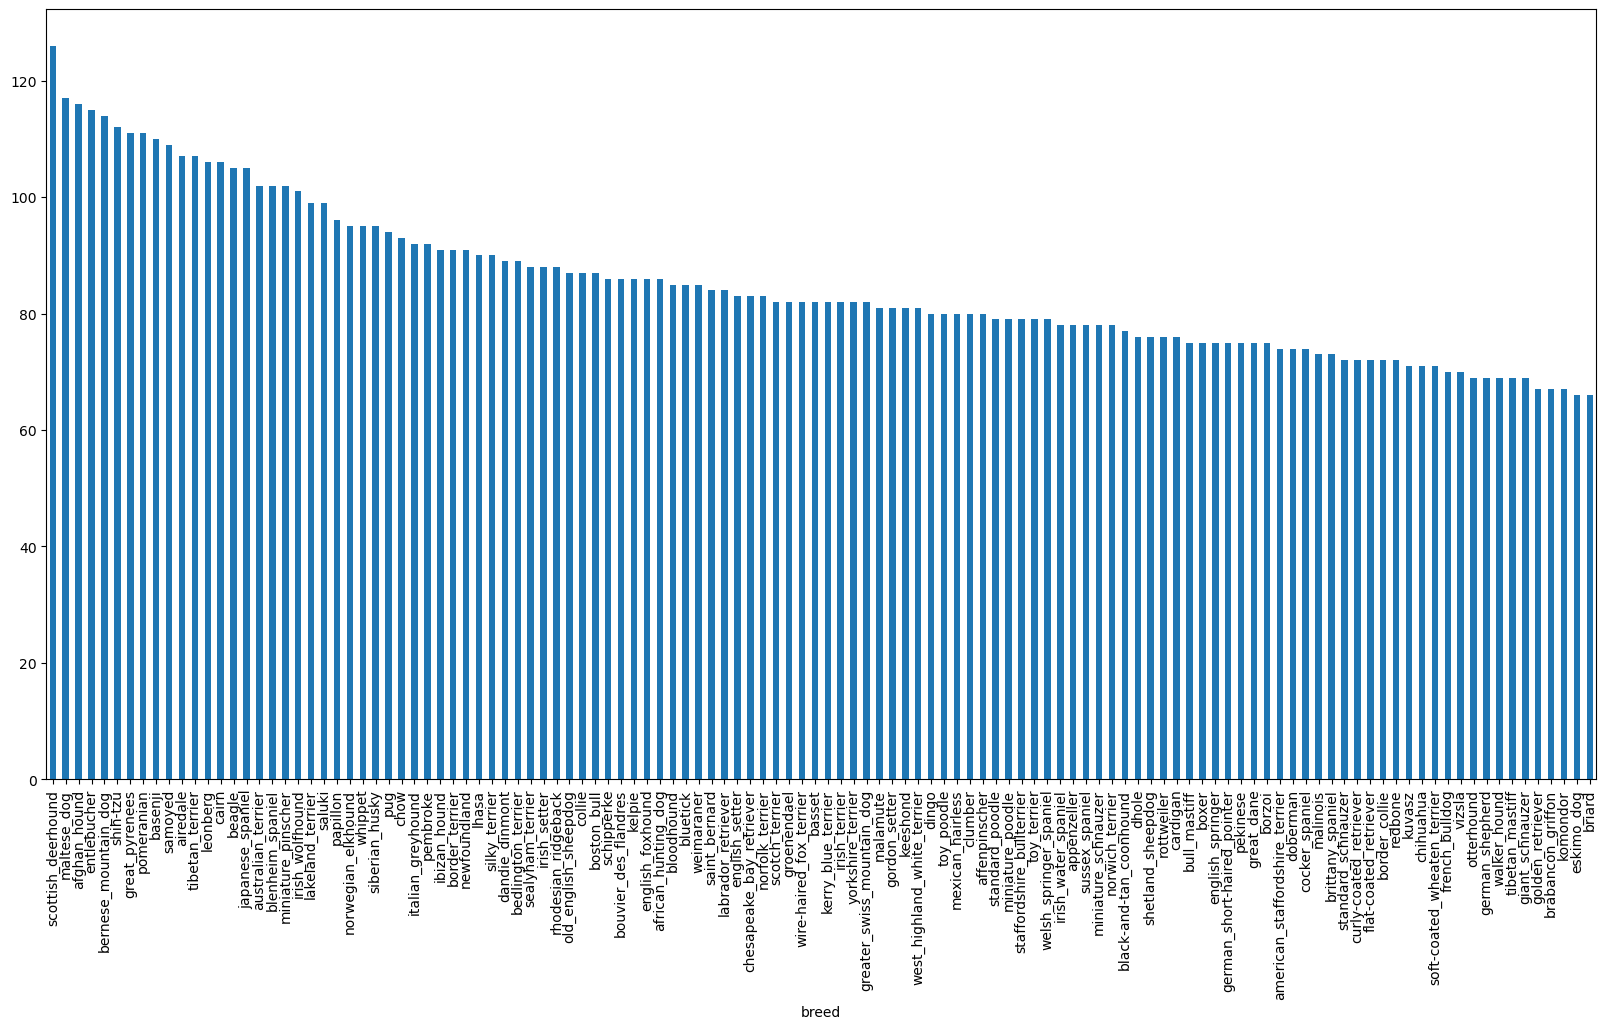

In [30]:
# How many images are there of each breed
labels_csv["breed"].value_counts().plot.bar(figsize=(20,10));

In [31]:
labels_csv["breed"].value_counts()

breed
scottish_deerhound      126
maltese_dog             117
afghan_hound            116
entlebucher             115
bernese_mountain_dog    114
                       ... 
golden_retriever         67
brabancon_griffon        67
komondor                 67
eskimo_dog               66
briard                   66
Name: count, Length: 120, dtype: int64

In [32]:
labels_csv["breed"].value_counts().median()

82.0

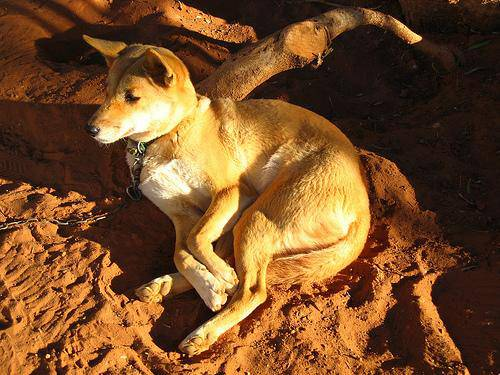

In [33]:
from IPython.display import Image
Image("/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg")

### Getting images and their labels

let's get a list of all our image file pathnames

In [34]:
# Create pathnames from images ID's
filenames  = [ "/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/" + fname + ".jpg" for fname in labels_csv["id"]]
filenames[:10]

['/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 '/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 '/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/001cdf01b096e06d78e9e5112d419397.jpg',
 '/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/00214f311d5d2247d5dfe4fe24b2303d.jpg',
 '/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/0021f9ceb3235effd7fcde7f7538ed62.jpg',
 '/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/002211c81b498ef88e1b40b9abf84e1d.jpg',
 '/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/00290d3e1fdd27226ba27a8ce248ce85.jpg',
 '/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML

In [35]:
#Check whether number of filenames matches number of actual image files
import os 
if len(os.listdir("/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/"))==len(filenames):
    print("Filenames match actual amount of files!!!  Proceed.")
else:
    print("Filenames do not match actual amount of files, check the target directory!")

Filenames match actual amount of files!!!  Proceed.


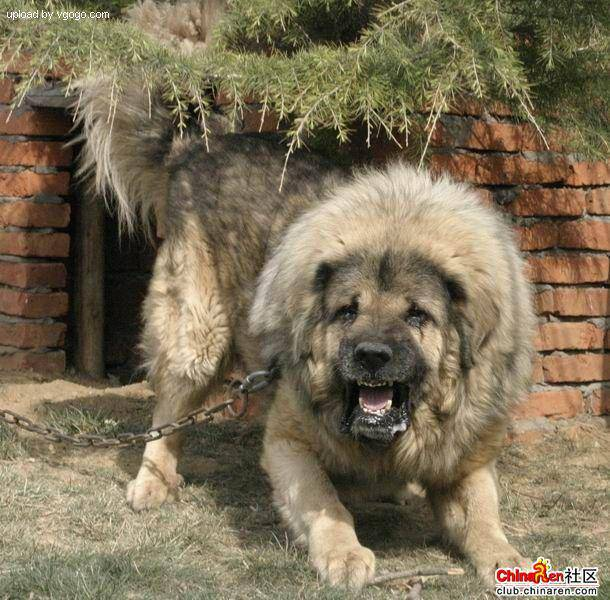

In [36]:
# One more check 
Image(filenames[9000])

In [37]:
import numpy as np
labels  = labels_csv["breed"].to_numpy()
# labels = np.array(labels)
labels


array(['boston_bull', 'dingo', 'pekinese', ..., 'airedale',
       'miniature_pinscher', 'chesapeake_bay_retriever'], dtype=object)

In [38]:
len(labels)

10222

In [39]:
# See if numbers of labels matches the number of filenames
if len(labels)==len(filenames):
    print("Number of labels matches of filename")
else:
    print("Number of labels does not matches of filename, check data directories")

Number of labels matches of filename


In [40]:
# find the unique labels value
unique_breeds = np.unique(labels)
len(unique_breeds)

120

In [41]:
# Turn a single label into an array of booleans
print(labels[0])
labels[0] == unique_breeds

boston_bull


array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False])

In [42]:
# Turn every label into a boolean array
boolean_labels = [label == unique_breeds for label in labels]
boolean_labels[:2]

[array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False,  True, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False]),
 array([False, False, False, False, False, Fal

In [43]:
len(boolean_labels)

10222

In [44]:
# Example: Turning boolean array into integers
print(labels[0]) # Original label
print(np.where(unique_breeds==labels[0])) # index where label occurs
print(boolean_labels[0].argmax()) # index where label accurs in boolean array
print(boolean_labels[0].astype(int)) # there will be a 1 where the sample label occurs

boston_bull
(array([19]),)
19
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0]


# Creating our Validation set!

In [45]:
# setup X & y variable
X = filenames
y = boolean_labels

In [46]:
len(filenames), len(boolean_labels)

(10222, 10222)

In [47]:
if len(filenames) == len(boolean_labels):
    print("Yeeeeey")

Yeeeeey


In [48]:
# set number of images to use for experimentating
NUM_IMAGES = 1000 #@param {type:"slider", min:1000, max:10000,step:1000} # for Colab only

NUM_IMAGES = 1000


In [49]:
# Lets split our data into train and validation sets
from sklearn.model_selection import train_test_split

np.random.seed(42)

# Split them into training an dvalidation of total size NUM_IMAGES
X_train,X_val,y_train,y_val = train_test_split(X[:NUM_IMAGES],y[:NUM_IMAGES], test_size=0.2,random_state=42)

len(X_train), len(y_train), len(X_val), len(y_val)

(800, 800, 200, 200)

In [50]:
X_train[:5], y_train[:2]

(['/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/00bee065dcec471f26394855c5c2f3de.jpg',
  '/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/0d2f9e12a2611d911d91a339074c8154.jpg',
  '/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/1108e48ce3e2d7d7fb527ae6e40ab486.jpg',
  '/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/0dc3196b4213a2733d7f4bdcd41699d3.jpg',
  '/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/146fbfac6b5b1f0de83a5d0c1b473377.jpg'],
 [array([False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False,  True,
         False, False, False, False, False, False, False, False, False,
         False, False, Fal

## Preprocessing Images (Turning images into Tensors)

To process our images into Tensors we're going to write a function which does a few things:

1. Take an image filepath as input
  2. Use tensoflow to read the file and save it to a variable, `image`
  3. Turn our `image` (a jpg) into Tensors
  4. Normalize our `image` (convert color channel values from 0-255 to 0-1)
  5. Resize the `image` to be a shape(224,224)
  6. Return the modified `image`

In [51]:
# convert images to NumPy array
from matplotlib.pyplot import imread
image = imread(filenames[42])

In [52]:
image.shape

(257, 350, 3)

In [53]:
image.max(), image.min()

(255, 0)

In [54]:
tf.constant(image)[:2]

2024-08-08 19:47:47.268684: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1886] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 735 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1080 Ti, pci bus id: 0000:05:00.0, compute capability: 6.1


<tf.Tensor: shape=(2, 350, 3), dtype=uint8, numpy=
array([[[ 89, 137,  89],
        [ 76, 124,  76],
        [ 63, 111,  61],
        ...,
        [ 77, 133,  86],
        [ 76, 134,  86],
        [ 76, 134,  86]],

       [[ 72, 119,  75],
        [ 67, 114,  68],
        [ 63, 110,  64],
        ...,
        [ 75, 131,  84],
        [ 74, 132,  84],
        [ 74, 132,  84]]], dtype=uint8)>

In [55]:
filenames[1]

'/home/haseebkhan2@ISB.MTBC.COM/Haseeb_Niazi/ML/ML_Projects/Dog_breed_classification/data/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg'

In [56]:
# Define image size
IMG_SIZE = 224

# Create a function for preprocessing images
def process_image(image_path , img_size=IMG_SIZE):
    """
    Take an image file path and turns the image into a Tensor.
    """
    # Read in an iamge file
    image = tf.io.read_file(image_path)
    # Turn the jpeg image into numerical Tensor with 3 colour channels (Red,Green,Blue)
    image = tf.image.decode_jpeg(image, channels=3)
    # Convert the colour channel values from 0-255 to 0-1 values
    image = tf.image.convert_image_dtype(image,tf.float32)
    # Resize the image to our desired value (224,224)
    image = tf.image.resize(image, size=[IMG_SIZE,IMG_SIZE])
    return image

In [57]:
tensor = tf.io.read_file(filenames[26])
tensor

<tf.Tensor: shape=(), dtype=string, numpy=b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00\xff\xdb\x00C\x00\n\x07\x07\x08\x07\x06\n\x08\x08\x08\x0b\n\n\x0b\x0e\x18\x10\x0e\r\r\x0e\x1d\x15\x16\x11\x18#\x1f%$"\x1f"!&+7/&)4)!"0A149;>>>%.DIC<H7=>;\xff\xdb\x00C\x01\n\x0b\x0b\x0e\r\x0e\x1c\x10\x10\x1c;("(;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;\xff\xc0\x00\x11\x08\x01\xf4\x01w\x03\x01"\x00\x02\x11\x01\x03\x11\x01\xff\xc4\x00\x1f\x00\x00\x01\x05\x01\x01\x01\x01\x01\x01\x00\x00\x00\x00\x00\x00\x00\x00\x01\x02\x03\x04\x05\x06\x07\x08\t\n\x0b\xff\xc4\x00\xb5\x10\x00\x02\x01\x03\x03\x02\x04\x03\x05\x05\x04\x04\x00\x00\x01}\x01\x02\x03\x00\x04\x11\x05\x12!1A\x06\x13Qa\x07"q\x142\x81\x91\xa1\x08#B\xb1\xc1\x15R\xd1\xf0$3br\x82\t\n\x16\x17\x18\x19\x1a%&\'()*456789:CDEFGHIJSTUVWXYZcdefghijstuvwxyz\x83\x84\x85\x86\x87\x88\x89\x8a\x92\x93\x94\x95\x96\x97\x98\x99\x9a\xa2\xa3\xa4\xa5\xa6\xa7\xa8\xa9\xaa\xb2\xb3\xb4\xb5\xb6\xb7\xb8\xb9\xba\xc2\xc3\xc4\xc5\xc6\xc7\xc8\xc9\xca

In [58]:
tensor = tf.image.decode_jpeg(tensor, channels=3)
tensor

<tf.Tensor: shape=(500, 375, 3), dtype=uint8, numpy=
array([[[ 59,  68,  65],
        [ 64,  73,  70],
        [ 71,  80,  77],
        ...,
        [115, 128, 108],
        [115, 128, 108],
        [110, 123, 103]],

       [[ 65,  74,  71],
        [ 72,  81,  78],
        [ 79,  88,  85],
        ...,
        [114, 127, 107],
        [117, 130, 110],
        [116, 129, 109]],

       [[ 68,  77,  74],
        [ 76,  85,  82],
        [ 83,  92,  89],
        ...,
        [114, 127, 107],
        [120, 133, 113],
        [123, 136, 116]],

       ...,

       [[173, 200, 155],
        [164, 179, 136],
        [181, 166, 133],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[142, 159, 117],
        [147, 154, 113],
        [189, 174, 141],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[167, 179, 139],
        [167, 172, 132],
        [204, 188, 155],
        ...,
        [255, 255, 25

In [59]:
tf.image.convert_image_dtype(tensor, tf.float32)

<tf.Tensor: shape=(500, 375, 3), dtype=float32, numpy=
array([[[0.23137257, 0.26666668, 0.25490198],
        [0.2509804 , 0.28627452, 0.27450982],
        [0.2784314 , 0.3137255 , 0.3019608 ],
        ...,
        [0.45098042, 0.5019608 , 0.42352945],
        [0.45098042, 0.5019608 , 0.42352945],
        [0.43137258, 0.48235297, 0.4039216 ]],

       [[0.25490198, 0.2901961 , 0.2784314 ],
        [0.28235295, 0.31764707, 0.30588236],
        [0.30980393, 0.34509805, 0.33333334],
        ...,
        [0.44705886, 0.49803925, 0.41960788],
        [0.45882356, 0.50980395, 0.43137258],
        [0.454902  , 0.5058824 , 0.427451  ]],

       [[0.26666668, 0.3019608 , 0.2901961 ],
        [0.29803923, 0.33333334, 0.32156864],
        [0.3254902 , 0.36078432, 0.34901962],
        ...,
        [0.44705886, 0.49803925, 0.41960788],
        [0.47058827, 0.52156866, 0.4431373 ],
        [0.48235297, 0.53333336, 0.454902  ]],

       ...,

       [[0.6784314 , 0.7843138 , 0.60784316],
        [0.64

## Turning our data into batches

Why turn our data into batches?

Let's say you're trying to process 10,000+ images in one go... they all might not fit into memory.

so that's why we do about 32 (this is batch size) images at a time (you can manually adjust the batch size if need be).

in order to use TensorFlow effectively, we need our data in the form of tensorFlow tuples which look like this:
`(image,label)`

In [60]:
# Create a simple function to return a tuple (image,label)
def get_image_label(image_path, label):
    """
    Takes an image file path name and the associated label,
    processes the image and returns a tuple of (image,label)
    """
    image = process_image(image_path)
    return image, label

In [61]:
# Demo of the above
(process_image(X[42]), tf.constant(y[42]))

(<tf.Tensor: shape=(224, 224, 3), dtype=float32, numpy=
 array([[[0.3264178 , 0.5222886 , 0.3232816 ],
         [0.2537167 , 0.44366494, 0.24117757],
         [0.25699762, 0.4467087 , 0.23893751],
         ...,
         [0.29325107, 0.5189916 , 0.3215547 ],
         [0.29721776, 0.52466875, 0.33030328],
         [0.2948505 , 0.5223015 , 0.33406618]],
 
        [[0.25903144, 0.4537807 , 0.27294815],
         [0.24375686, 0.4407019 , 0.2554778 ],
         [0.2838985 , 0.47213382, 0.28298813],
         ...,
         [0.2785345 , 0.5027992 , 0.31004712],
         [0.28428748, 0.5108719 , 0.32523635],
         [0.28821915, 0.5148036 , 0.32916805]],
 
        [[0.20941195, 0.40692952, 0.25792548],
         [0.24045378, 0.43900946, 0.2868911 ],
         [0.29001117, 0.47937486, 0.32247734],
         ...,
         [0.26074055, 0.48414773, 0.30125174],
         [0.27101526, 0.49454468, 0.32096273],
         [0.27939945, 0.5029289 , 0.32934693]],
 
        ...,
 
        [[0.00634795, 0.03442048

**Now we've got a way to turn our data into tuples of Tensors in the form: `(image, label)`, let's make a function to turn all our data (`X`&`y`) into batches!**


In machine learning, especially in deep learning, data shuffling plays a critical role in ensuring that the training process is efficient and effective. However, there are specific reasons why we don't shuffle validation and test data:

**Training Data**
Why Shuffle: Shuffling the training data ensures that each batch contains a diverse mix of samples. This helps to reduce the likelihood of the model learning patterns that are specific to the order of the training data, thus promoting better generalization.

**Validation Data**
Why Not Shuffle: The validation set is used to evaluate the model's performance during training. By not shuffling the validation data, you ensure that the evaluation is consistent and reliable across different epochs. This consistency is important for tracking the model's performance over time and making decisions about hyperparameter tuning or early stopping.

**Test Data**
Why Not Shuffle: The test set is used to evaluate the final performance of the model after training is complete. Like the validation set, the test data should remain in a fixed order to ensure that the evaluation is consistent and reproducible. Shuffling the test data could lead to variations in performance metrics due to different sample orders, which is undesirable for final model evaluation.

**Summary**
Training Data: Shuffle to ensure diverse batches and better generalization.
Validation Data: Do not shuffle to maintain consistent and reliable performance evaluation.
Test Data: Do not shuffle to ensure consistent and reproducible final performance evaluation.

In [62]:
# Define the batch size, 32 is a good start
BATCH_SIZE = 32

# Create a function to turn data into batches
def create_data_batches(X,y=None, batch_size = BATCH_SIZE, valid_data = False, test_data=False):
    """
    Creates batches of data out of image (X) and label (y) pairs.
    Shuffles the data if it's training data but doesn't shuffle if its validation data.
    Also accepts tets data as input (no labels).
    """
    # if the data is a test dataset, we probably don't have labels
    if test_data:
        print("Creating test data batches...")
        data = tf.data.Dataset.from_tensor_slices((tf.constant(X))) # only filepaths (no labels)
        data_batch = data.map(process_image).batch(BATCH_SIZE)
        return data_batch

    # if the data is validation dataset, we don't need to shuffle it
    elif valid_data:
        print("Creating validation data batches...")
        data = tf.data.Dataset.from_tensor_slices((tf.constant(X), # filepaths
                                                   tf.constant(y))) # labels
        data_batch = data.map(get_image_label).batch(BATCH_SIZE)
        return data_batch
    else:
        print("Creating training data batches...")
        # trun filepaths and labels into Tensors
        data = tf.data.Dataset.from_tensor_slices((tf.constant(X),
                                                  tf.constant(y)))
        # shuffling pathnames and labels before mapping image processor function is faster than shuffling image
        data = data.shuffle(buffer_size=len(X))
        # create (Image,label) tuple (this also turns the image path into a preprocessed image)
        data = data.map(get_image_label)
        # Turn the training data into batches
        data_batch = data.batch(BATCH_SIZE)
    return data_batch
        

In [63]:
# Creating training and validation data batches
train_data = create_data_batches(X_train,y_train)
val_data = create_data_batches(X_val,y_val, valid_data=True)

Creating training data batches...
Creating validation data batches...


In [64]:
# check out the different attributes of our data batches
train_data.element_spec, val_data.element_spec

((TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)),
 (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)))

## Visualizaing Data Batches

Our data in now in batches, however, these can be a little hard to understand/ comprehend, lets visualize them

In [65]:
import matplotlib.pyplot as plt

# Create a function for viewing images in a data batch
def show_25_images(images, labels):
    """
    Displays a plot of 25 images and their lables from a data batch.
    """
    # setup the figure
    plt.figure(figsize=(10,10))
    # loop through 25 (for displaying 25 images)
    for i in range(25):
        # create subplots (5 rows, 5 columns)
        ax = plt.subplot(5,5, i+1)
        # Display an image
        plt.imshow(images[i])
        # Add the image label as the little
        plt.title(unique_breeds[labels[i].argmax()])
        # turn the grid lines off
        plt.axis("off")

In [66]:
train_images, train_labels = next(train_data.as_numpy_iterator())
len(train_images), len(train_labels)

(32, 32)

In [67]:
train_data

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

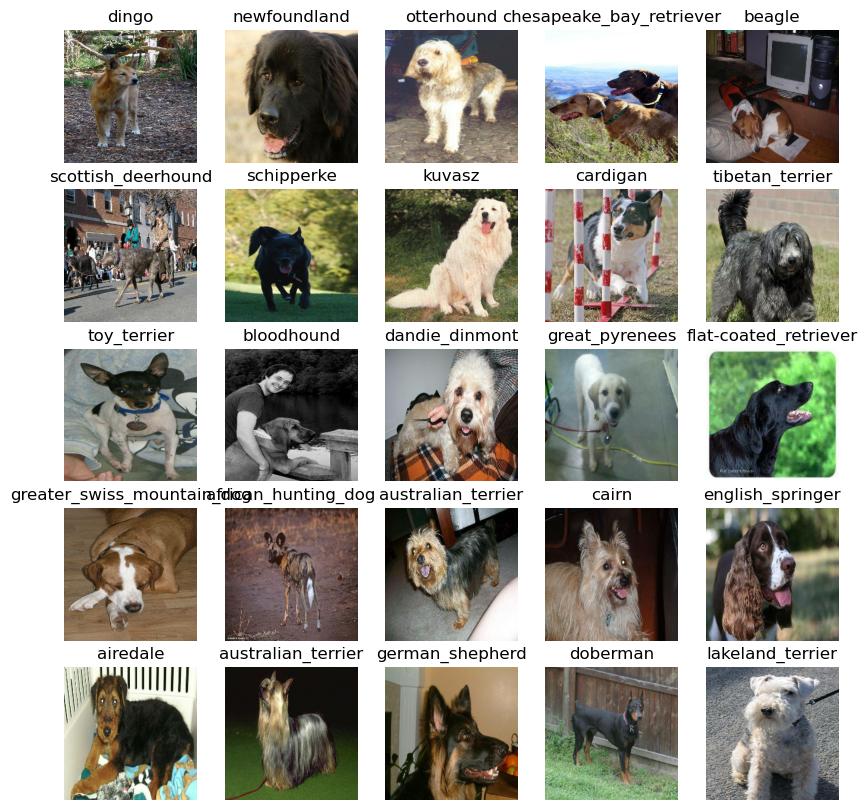

In [68]:
# Now lets visualize the data in training batch
show_25_images(train_images,train_labels)

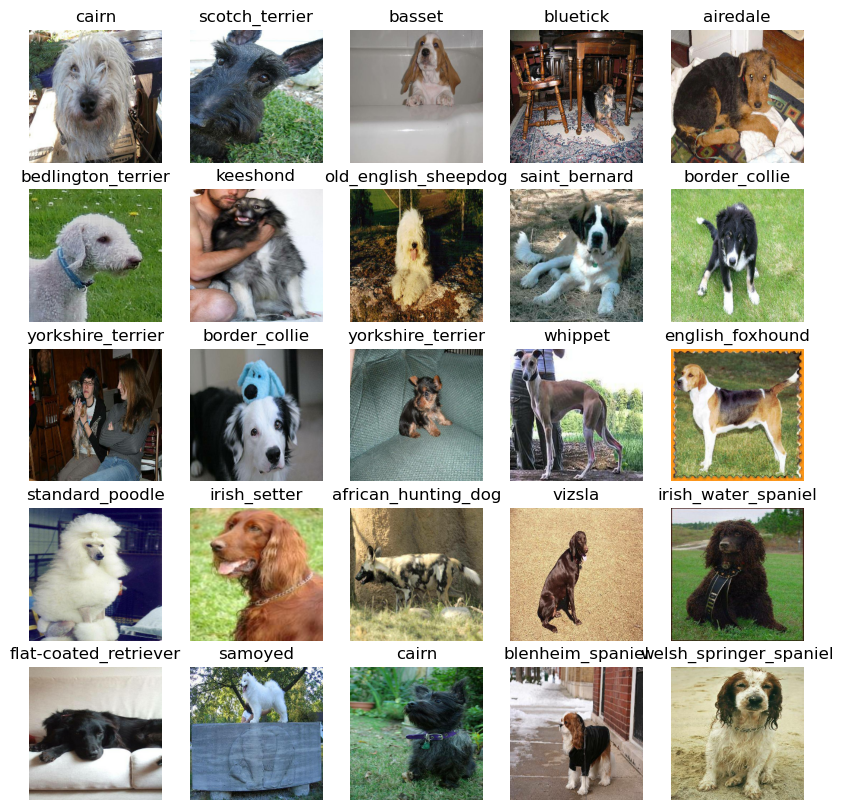

In [69]:
# Now lets visualize the data in validation set
val_images, val_lables = next(val_data.as_numpy_iterator())
show_25_images(val_images, val_lables)

In [70]:
unique_breeds

array(['affenpinscher', 'afghan_hound', 'african_hunting_dog', 'airedale',
       'american_staffordshire_terrier', 'appenzeller',
       'australian_terrier', 'basenji', 'basset', 'beagle',
       'bedlington_terrier', 'bernese_mountain_dog',
       'black-and-tan_coonhound', 'blenheim_spaniel', 'bloodhound',
       'bluetick', 'border_collie', 'border_terrier', 'borzoi',
       'boston_bull', 'bouvier_des_flandres', 'boxer',
       'brabancon_griffon', 'briard', 'brittany_spaniel', 'bull_mastiff',
       'cairn', 'cardigan', 'chesapeake_bay_retriever', 'chihuahua',
       'chow', 'clumber', 'cocker_spaniel', 'collie',
       'curly-coated_retriever', 'dandie_dinmont', 'dhole', 'dingo',
       'doberman', 'english_foxhound', 'english_setter',
       'english_springer', 'entlebucher', 'eskimo_dog',
       'flat-coated_retriever', 'french_bulldog', 'german_shepherd',
       'german_short-haired_pointer', 'giant_schnauzer',
       'golden_retriever', 'gordon_setter', 'great_dane',
      

## Building a model

Before we build a model, there are a few things we need to define:
* input shape (our images shape, in the form of Tensors) to our model.
* The output shape(Image labels, in the form of Tensors) of our model.
* The URL of the model we want to use.

In [74]:
# Setup input shape to the model
INPUT_SHAPE = [IMG_SIZE,IMG_SIZE,3] # batch, height, width, colour channels

# setup output shape of our model
OUTPUT_SHAPE = len(unique_breeds)

# Setup model URL from TesorFlow Hub
MODEL_URL = "https://www.kaggle.com/models/google/mobilenet-v2/TensorFlow2/130-224-classification/2"

Now we've got our inputs, outputs and model ready to go.
Lets put them together into a Keras deep learning model!

Knowing this, lets create a function which:
* Takes the input shape, output shape and the model we've chosen as parameters.
* Defines the layers in a Keras model in Sequential fashion (do this first, then this, then that).
* Compiles the model (says it should be evaluated and improved).
* Builds the model (tells the model the input shape it'll be getting)
* Returns the model

In [75]:
# Cretae a function which builds a Keras model
def create_model(input_shape=INPUT_SHAPE, output_shape=OUTPUT_SHAPE, model_url= MODEL_URL):
    print("Building model with:", MODEL_URL)

    model = tf.keras.Sequential([
        hub.KerasLayer(model_url, input_shape=input_shape, trainable=False),  # Layer 1 (input layer)
        tf.keras.layers.Dense(units=output_shape, activation="softmax")  # Layer 2 (output layer)
    ])

    # Compile the model
    model.compile(loss=tf.keras.losses.CategoricalCrossentropy(),
                  optimizer=tf.keras.optimizers.Adam(),
                  metrics=["accuracy"])

    return model

In [76]:
model = create_model()
model.summary()

Building model with: https://www.kaggle.com/models/google/mobilenet-v2/TensorFlow2/130-224-classification/2
Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer_1 (KerasLayer)  (None, 1001)              5432713   
                                                                 
 dense_1 (Dense)             (None, 120)               120240    
                                                                 
Total params: 5552953 (21.18 MB)
Trainable params: 120240 (469.69 KB)
Non-trainable params: 5432713 (20.72 MB)
_________________________________________________________________


In [77]:
INPUT_SHAPE

[224, 224, 3]